![Banner](../../../../Images/Banner/07_remote_sensing/09_05_banner_rs_hyperspect.png)


# Biophysical and Biochemical Trait Retrieval

Indices give relative answers; many applications need numbers: leaf area index (LAI) in m² m⁻²,
chlorophyll in µg cm⁻², water in g cm⁻². This notebook simulates canopy spectra with the PROSAIL
radiative transfer model, studies which wavelengths carry each trait, trains partial least squares,
random forest and Gaussian process regression models on a simulated look-up table, and applies a
hybrid (radiative transfer plus machine learning) retrieval to a Tanager scene, with per pixel
uncertainty and a check of where the model can be trusted.


## Overview

### Three routes from spectra to traits

| Approach | How | Strengths | Weaknesses |
|---|---|---|---|
| Empirical | Regress field measured traits on image spectra (PLSR, ML) | Accurate where calibrated | Needs field data; site and date specific |
| Physical | Invert a radiative transfer model (look-up table or optimisation) | Transferable, no field data | Ill posed (different parameter sets give similar spectra); slow |
| Hybrid | Train a fast regressor on simulated spectra, apply to images | Transferable, fast, gives uncertainty (GPR) | Only as good as the model's assumptions and parameter ranges |

### PROSAIL

**PROSPECT** (here version D, Féret et al. 2017) models a leaf as a stack of `N` layers with
chlorophyll `cab`, carotenoids `car`, anthocyanins `ant`, brown pigments `cbrown`, equivalent water
thickness `cw` and dry matter `cm`. **4SAIL** (Verhoef 1984; Verhoef et al. 2007) turns leaf
optics into canopy reflectance from `lai`, the mean leaf angle `lidfa`, the hot spot parameter, soil
brightness and moisture (`rsoil`, `psoil`) and the sun and view geometry. Together they reproduce
the main features of a canopy spectrum: the red edge moves with `cab`, the NIR rises with `lai`,
the SWIR falls with `cw` and the dry matter features follow `cm`.

### Regressors

- **Partial least squares regression (PLSR)** projects the spectra onto a few latent components that
  covary with the trait. The number of components is chosen by cross validation; **variable
  importance in projection (VIP)** scores above about 1 mark influential bands.
- **Random forests** handle non linearity but extrapolate poorly.
- **Gaussian process regression (GPR)** gives a prediction and a standard deviation for every pixel,
  which flags spectra unlike the training data (Verrelst et al. 2015).

### Validation

A model trained on simulations has to be validated against field measurements (destructive LAI,
SPAD or extracted chlorophyll, leaf water) before its absolute values are used. Without field data,
the honest checks are internal (how well the model inverts independent simulations) and physical
(do the maps make sense and agree with indices).


## Trait Retrieval with GeoLattice

`hs.prosail_spectrum` and `hs.prosail_lut` run PROSAIL (it needs `pip install prosail`) and
convolve the spectra to a cube's bands. `hs.fit_plsr` and `hs.fit_regressor` return a `TraitModel`
with cross validated metrics and a `predict_map` method; `hs.hybrid_retrieval` does the whole
hybrid chain in one call; `hs.vip_scores` explains PLSR models.

### Learning objectives

1. Run PROSAIL and see how LAI, chlorophyll, water and dry matter change a canopy spectrum.
2. Locate the wavelengths that carry each trait with a global sensitivity analysis.
3. Build a noisy look-up table on Tanager bands for the scene's sun and view geometry.
4. Train and compare PLSR, random forest and GPR models, and interpret VIP scores.
5. Map LAI, chlorophyll and leaf water with uncertainty by hybrid retrieval.
6. Flag pixels whose spectra the model was not trained for.

### Data

| Dataset | Use |
|---|---|
| Tanager agriculture scene (Gran Chaco, 24 February 2025), 250 by 250 pixel window | Image to retrieve traits from; sun and view angles from the ancillary layers |

No field measurements come with the scene, so all accuracy figures here are for simulated data.

### Contents

- Setup
- The PROSAIL forward model
- Which wavelengths carry which trait?
- A look-up table for the scene
- PLSR and variable importance
- Random forest and Gaussian process regression
- Hybrid retrieval on the Tanager scene
- Where can the model be trusted?
- Summary and exercises


## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings

from pathlib import Path  # file paths

import numpy as np  # arrays
import pandas as pd  # tables
import matplotlib.pyplot as plt  # figures

import geolattice  # GeoLattice
from geolattice.rsense import hyperspectral as hs  # hyperspectral cubes, readers and tools

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
DATA = Path("../../../../Data/08_remote_sensing/08_05_HyperSpectral")  # data folder next to this notebook
TANAGER = DATA / "Tanger"  # Planet Tanager sample scenes
OUT = Path("outputs")  # results written by this notebook
OUT.mkdir(exist_ok=True)  # create it if needed


def tanager_file(category, product="sr"):
    """Path of a Tanager product (sr or radiance) for a scene category folder."""
    return next((TANAGER / category).glob(f"*/*_ortho_{product}_hdf5.h5"))


print("GeoLattice", geolattice.__version__)  # library version used for this notebook

import time  # timing
from scipy.stats import spearmanr  # rank correlation

GeoLattice 0.3.43


## The PROSAIL forward model


In [2]:
WIN = (slice(200, 450), slice(300, 550))  # 250 x 250 pixels, 7.5 x 7.5 km
cube = hs.read_tanager(tanager_file("agriculture"), window=WIN)
cube = hs.drop_bad_bands(cube)  # good bands between 400 and 2450 nm
anc = hs.read_tanager_ancillary(tanager_file("agriculture"), window=WIN)
tts = float(anc["sun_zenith"].mean())  # solar zenith (deg)
tto = float(anc["sensor_zenith"].mean())  # view zenith (deg)
psi = float(abs(anc["sun_azimuth"].mean() - anc["sensor_azimuth"].mean()) % 360)  # relative azimuth (deg)
psi = 360 - psi if psi > 180 else psi
print(cube.shape, f"| sun zenith {tts:.1f}, view zenith {tto:.1f}, relative azimuth {psi:.1f} deg")
wl = hs.wavelengths(cube)

(350, 250, 250) | sun zenith 26.4, view zenith 9.2, relative azimuth 49.0 deg


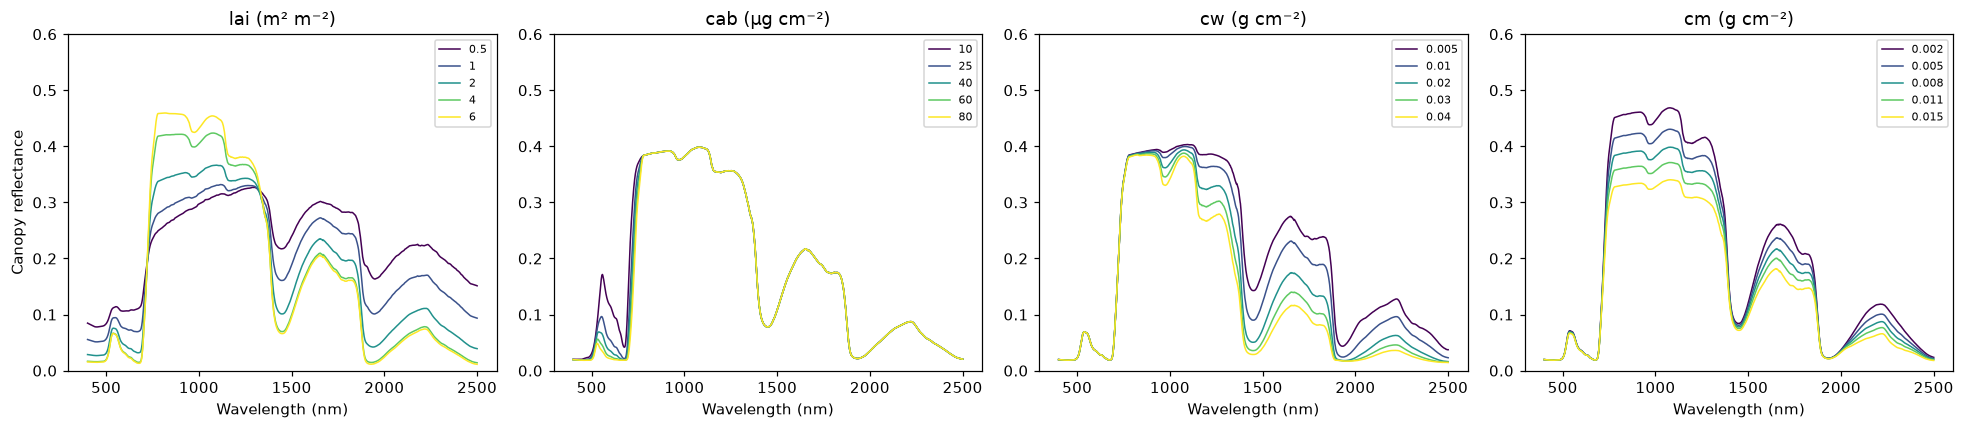

In [3]:
base = dict(lai=3.0, cab=40.0, cw=0.012, cm=0.008)  # a typical green canopy
sweeps = {"lai": [0.5, 1, 2, 4, 6], "cab": [10, 25, 40, 60, 80], "cw": [0.005, 0.01, 0.02, 0.03, 0.04],
          "cm": [0.002, 0.005, 0.008, 0.011, 0.015]}
units = {"lai": "m² m⁻²", "cab": "µg cm⁻²", "cw": "g cm⁻²", "cm": "g cm⁻²"}
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (p, vals) in zip(axes, sweeps.items()):
    for i, v in enumerate(vals):
        r = hs.prosail_spectrum(wavelengths_nm=np.arange(400, 2501), tts=tts, tto=tto, psi=psi, **{**base, p: v})
        ax.plot(np.arange(400, 2501), r, color=plt.cm.viridis(i / 4), lw=1, label=f"{v}")
    ax.set(title=f"{p} ({units[p]})", xlabel="Wavelength (nm)", ylim=(0, 0.6))
    ax.legend(fontsize=7)
axes[0].set_ylabel("Canopy reflectance")
plt.tight_layout()
plt.show()

Each parameter leaves its own mark. LAI raises the NIR plateau and deepens the SWIR water bands as
more leaves stack up; chlorophyll changes the visible and the position of the red edge but leaves
the NIR almost unchanged; leaf water acts only beyond about 1000 nm; dry matter darkens the NIR and
SWIR together. That is why a full spectrum carries information on all four at once, and why a
single index cannot separate them.


## Which wavelengths carry which trait?

A Latin hypercube look-up table varies all parameters together over their default ranges. The rank
correlation between each band and each parameter shows where the parameter can be seen through
everything else that varies.


3000 simulations on 350 bands in 3.4 s


,n,cab,car,cbrown,cw,cm,lai,lidfa,hspot,psoil,rsoil,ant
min,1.2,10.012,2.006,0.0,0.005,0.002,0.202,30.002,0.01,0.0,0.5,0.001
max,2.2,79.993,19.998,0.5,0.040,0.015,6.999,69.993,0.30,1.0,1.5,4.999


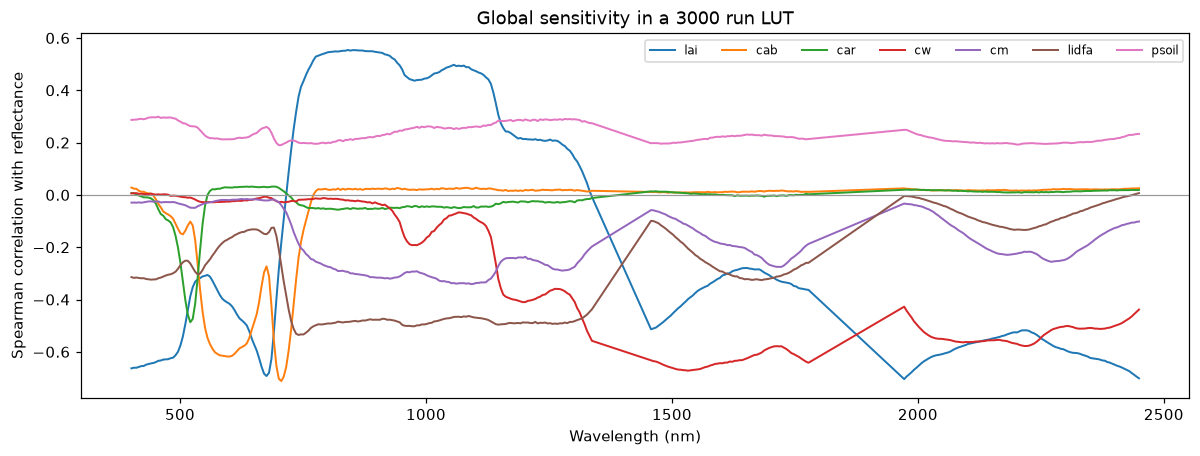

In [4]:
t0 = time.perf_counter()
P, S, lut_wl = hs.prosail_lut(3000, cube=cube, tts=tts, tto=tto, psi=psi, noise=0.02, seed=1)  # noisy LUT on Tanager bands
print(f"{len(P)} simulations on {S.shape[1]} bands in {time.perf_counter() - t0:.1f} s")
display(P.describe().loc[["min", "max"]].round(3))
traits = ["lai", "cab", "car", "cw", "cm", "lidfa", "psoil"]
rho = pd.DataFrame({t: [spearmanr(S[:, b], P[t])[0] for b in range(S.shape[1])] for t in traits}, index=lut_wl)
fig, ax = plt.subplots(figsize=(13, 4.3))
for t in traits:
    ax.plot(rho.index, rho[t], lw=1.3, label=t)
ax.axhline(0, color="0.6", lw=0.8)
ax.set(xlabel="Wavelength (nm)", ylabel="Spearman correlation with reflectance", title="Global sensitivity in a 3000 run LUT")
ax.legend(ncol=7, fontsize=8)
plt.show()

Across the whole table, LAI correlates positively with the NIR and negatively with the visible;
chlorophyll is visible mainly on the red edge and in the green, where its correlation is strongly
negative; leaf water and dry matter dominate parts of the SWIR; soil moisture (`psoil`) matters
where canopies are sparse. Carotenoids and leaf angle have weak, overlapping signatures, so they will
be hard to retrieve. These curves already predict which traits the models below can estimate well.


## A look-up table for the scene

The table above is split: 2000 simulations to train and 1000 to test. The 2 percent multiplicative
noise mimics sensor and atmospheric error, so the test measures how well a model inverts noisy
spectra it has not seen.


In [5]:
rng = np.random.default_rng(0)
order = rng.permutation(len(P))
tr, te = order[:2000], order[2000:]  # train and test simulations
Str = pd.DataFrame(S[tr], columns=lut_wl)  # training spectra with wavelength columns
Ste = S[te]


def test_metrics(model, trait):
    """R2 and RMSE of a TraitModel on the held-out simulations."""
    y, p = P[trait].to_numpy()[te], model.predict(Ste)
    return {"R2": 1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2), "RMSE": np.sqrt(np.mean((y - p) ** 2))}

## PLSR and variable importance


In [6]:
pls = {t: hs.fit_plsr(Str, P[t].to_numpy()[tr], target=t, max_components=25) for t in ["lai", "cab", "cw", "cm", "car"]}
rows = [{"trait": t, "components": m.metrics["n_components"], "CV R2": m.metrics["r2"],
         **{f"test {k}": v for k, v in test_metrics(m, t).items()}} for t, m in pls.items()]
pd.DataFrame(rows).set_index("trait").round(3)

,components,CV R2,test R2,test RMSE
trait,,,,
lai,10,0.828,0.821,0.827
cab,9,0.805,0.799,8.941
cw,7,0.777,0.799,0.005
cm,10,0.732,0.714,0.002
car,9,0.650,0.668,2.963


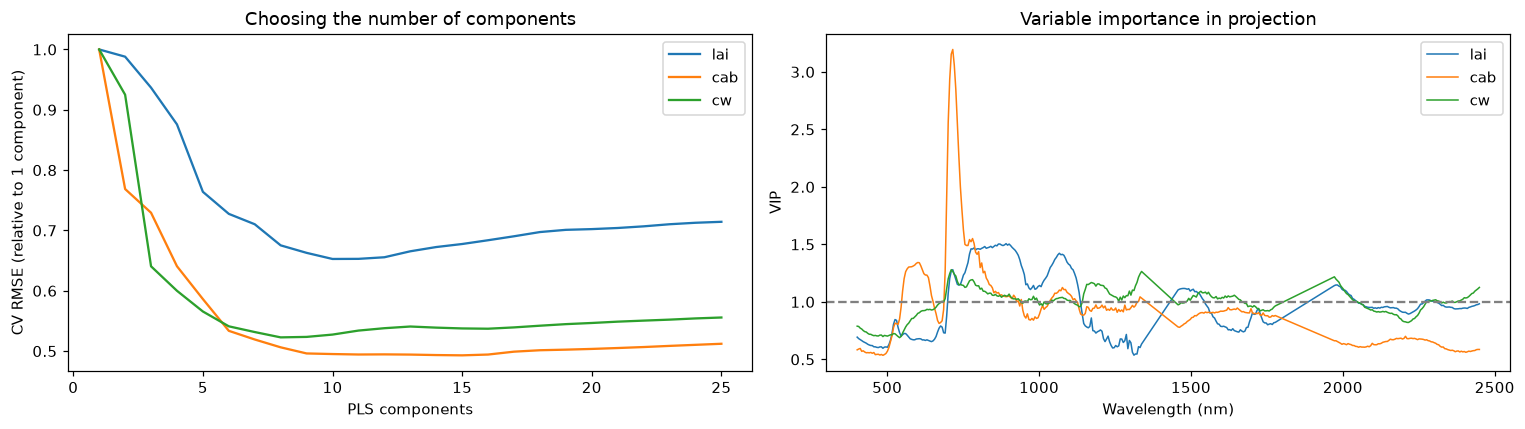

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for t in ["lai", "cab", "cw"]:
    press = pls[t].extra["press"]
    axes[0].plot(press["n_components"], press["rmse_cv"] / press["rmse_cv"].iloc[0], label=t)
    axes[1].plot(pls[t].extra["vip"].index, pls[t].extra["vip"].values, lw=1, label=t)
axes[0].set(xlabel="PLS components", ylabel="CV RMSE (relative to 1 component)", title="Choosing the number of components")
axes[1].axhline(1, color="0.5", ls="--")
axes[1].set(xlabel="Wavelength (nm)", ylabel="VIP", title="Variable importance in projection")
axes[0].legend(); axes[1].legend()
plt.tight_layout()
plt.show()

PLSR inverts LAI, chlorophyll and leaf water from noisy simulations with test R² of about 0.8, dry
matter less well (about 0.71) and carotenoids least well (about 0.67), matching the sensitivity
analysis. The cross validation curves reach their minimum at about 8 to 15 components, and the selection rule keeps the smallest model within one
standard error of the best. The VIP curves point to the same regions as the sensitivity plot: the
red edge and green for chlorophyll, the NIR and SWIR for LAI and leaf water.


## Random forest and Gaussian process regression


In [8]:
rows = []
models = {}
for t in ["lai", "cab", "cw"]:
    for name in ["rf", "gpr"]:
        n_fit = 2000 if name == "rf" else 800  # GPR scales with n^3; 800 runs keep it quick
        sub = rng.choice(len(tr), n_fit, replace=False)
        t0 = time.perf_counter()
        m = hs.fit_regressor(Str.iloc[sub], P[t].to_numpy()[tr][sub], target=t, model=name, cv=3)
        models[(t, name)] = m
        rows.append({"trait": t, "model": name, "train size": n_fit, "fit s": round(time.perf_counter() - t0, 1),
                     **{f"test {k}": v for k, v in test_metrics(m, t).items()}})
    rows.append({"trait": t, "model": "plsr", "train size": 2000, "fit s": np.nan,
                 **{f"test {k}": v for k, v in test_metrics(pls[t], t).items()}})
pd.DataFrame(rows).set_index(["trait", "model"]).round(3)

train size  fit s  test R2  test RMSE
trait model                                       
lai   rf           2000   14.2    0.838      0.787
      gpr           800    4.1    0.891      0.644
      plsr         2000    NaN    0.821      0.827
cab   rf           2000   14.5    0.862      7.412
      gpr           800    4.3    0.893      6.532
      plsr         2000    NaN    0.799      8.941
cw    rf           2000   13.1    0.868      0.004
      gpr           800    4.0    0.908      0.003
      plsr         2000    NaN    0.799      0.005

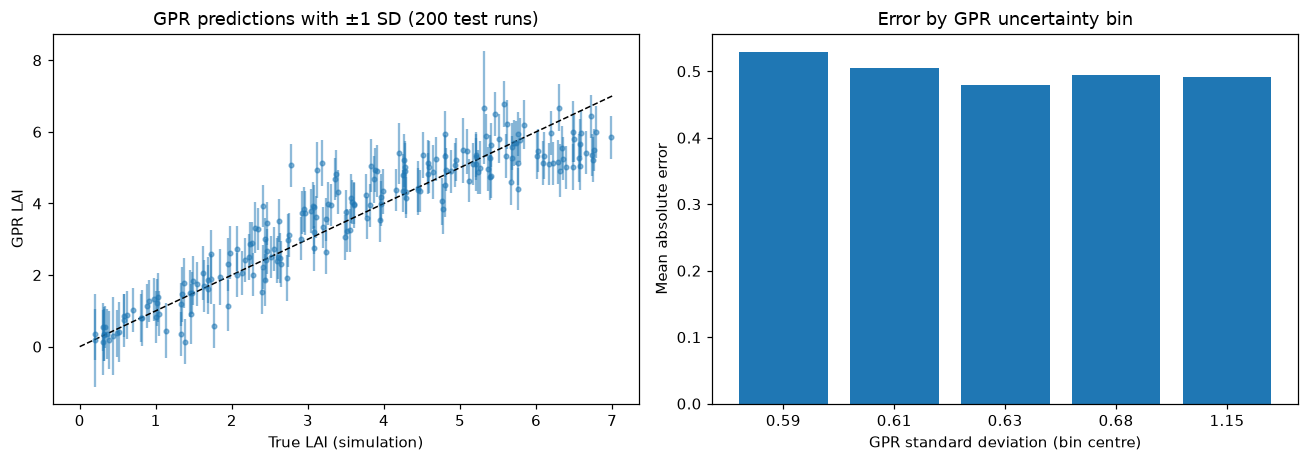

In [9]:
g = models[("lai", "gpr")]
mean, sd = g.model.predict(g._prep(Ste), return_std=True)  # prediction and standard deviation
y = P["lai"].to_numpy()[te]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
axes[0].errorbar(y[:200], mean[:200], yerr=sd[:200], fmt="o", ms=3, alpha=0.5)
axes[0].plot([0, 7], [0, 7], "k--", lw=1)
axes[0].set(xlabel="True LAI (simulation)", ylabel="GPR LAI", title="GPR predictions with ±1 SD (200 test runs)")
bins = pd.qcut(sd, 5)
err = pd.Series(np.abs(mean - y)).groupby(bins, observed=True).mean()
axes[1].bar(range(5), err.values)
axes[1].set_xticks(range(5), [f"{iv.mid:.2f}" for iv in err.index])
axes[1].set(xlabel="GPR standard deviation (bin centre)", ylabel="Mean absolute error", title="Error by GPR uncertainty bin")
plt.tight_layout()
plt.show()

GPR is the most accurate of the three for all three traits (test R² about 0.89 to 0.91), even though
it is fitted on 800 runs instead of 2000 because its cost grows with the cube of the training size;
PLSR, a linear model, is the least accurate. The GPR standard deviation, however, says little about
the error *inside* the training space: the mean absolute error is almost the same in every
uncertainty bin. The uncertainty mainly reflects the density of training samples, so it is most
useful for spotting spectra unlike any training sample, as below. The scatter plot also shows the
optical saturation of LAI: above about 5 the predictions flatten and underestimate.


## Hybrid retrieval on the Tanager scene

`hs.hybrid_retrieval` repeats these steps (LUT, noise, training) and applies the models to every
pixel. GPR is used for its uncertainty.


done in 41 s | ['lai', 'lai_std', 'cab', 'cab_std', 'cw', 'cw_std']


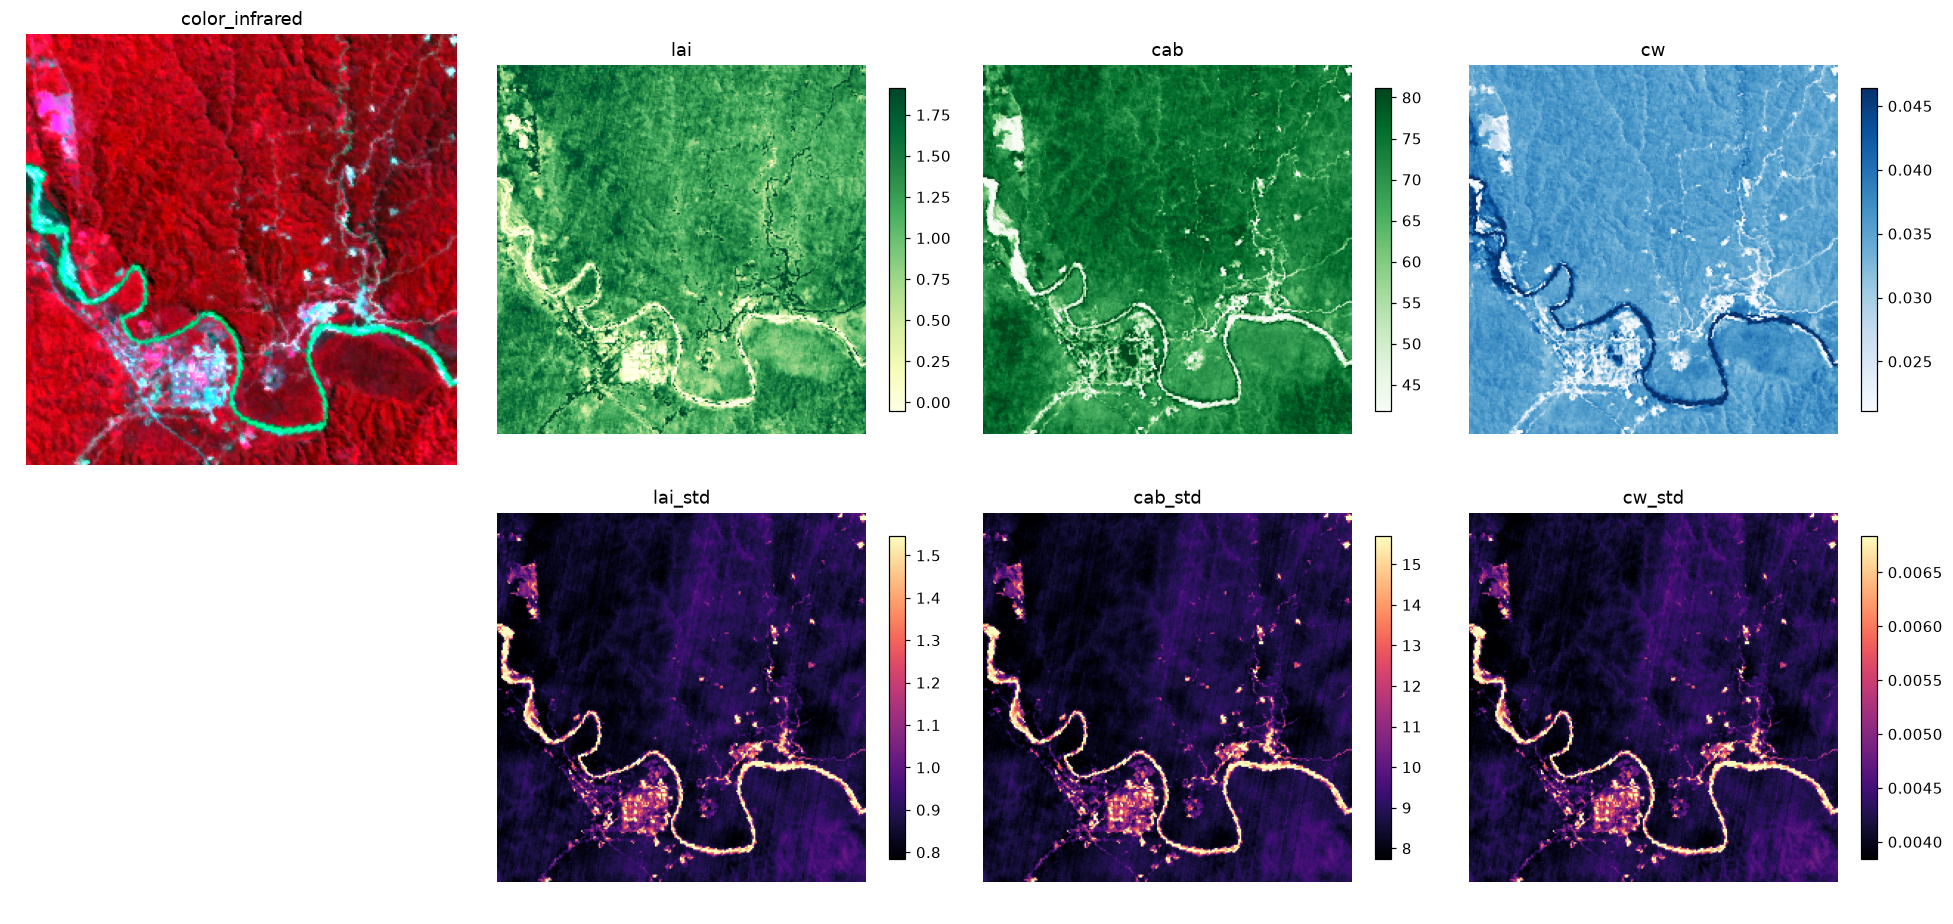

,lai,cab,cw
count,62500.000,62500.000,62500.000
mean,1.211,71.739,0.035
std,0.414,8.748,0.005
min,-2.095,8.593,-0.004
25%,1.061,70.111,0.034
50%,1.253,73.733,0.035
75%,1.435,76.379,0.037
max,4.062,127.461,0.070


In [10]:
t0 = time.perf_counter()
hyb = hs.hybrid_retrieval(cube, ("lai", "cab", "cw"), n=2000, model="gpr", n_train=800, noise=0.02,
                          tts=tts, tto=tto, psi=psi, return_std=True, seed=2)
maps = hyb["maps"]
print(f"done in {time.perf_counter() - t0:.0f} s |", list(maps.data_vars))
fig, axes = plt.subplots(2, 4, figsize=(18, 8.5))
hs.plot_rgb(cube, "color_infrared", ax=axes[0, 0])
axes[1, 0].axis("off")
for j, (t, cmap) in enumerate([("lai", "YlGn"), ("cab", "Greens"), ("cw", "Blues")], start=1):
    for i, var in enumerate([t, f"{t}_std"]):
        img = maps[var]
        im = axes[i, j].imshow(img, cmap=cmap if i == 0 else "magma", vmin=np.nanpercentile(img, 2), vmax=np.nanpercentile(img, 98))
        axes[i, j].set_title(var); axes[i, j].axis("off"); plt.colorbar(im, ax=axes[i, j], shrink=0.75)
plt.tight_layout()
plt.show()
maps.to_dataframe()[["lai", "cab", "cw"]].describe().round(3)

In [11]:
check = hs.index(cube, ["NDVI", "MTCI", "NDII"]).to_dataframe()[["NDVI", "MTCI", "NDII"]]
check = check.join(maps.to_dataframe()[["lai", "cab", "cw"]]).dropna()
rho = check.corr(method="spearman").loc[["NDVI", "MTCI", "NDII"], ["lai", "cab", "cw"]]
rho.round(2)

,lai,cab,cw
NDVI,0.58,0.44,0.14
MTCI,0.58,0.75,0.19
NDII,0.58,0.55,0.47


The patterns look right: the forest is greener and wetter than the town, the clearings and the
river, the uncertainty is highest over the river and the town, and the traits correlate with their
indices (chlorophyll with MTCI best, r about 0.75). The numbers do not. A closed tropical forest
should have an LAI of about 4 to 6, yet the median retrieved LAI is close to 1.25, while chlorophyll
and leaf water pile up near the top of their simulated ranges (and the GPR even extrapolates beyond
80 µg cm⁻²). The next cell looks for the reason.


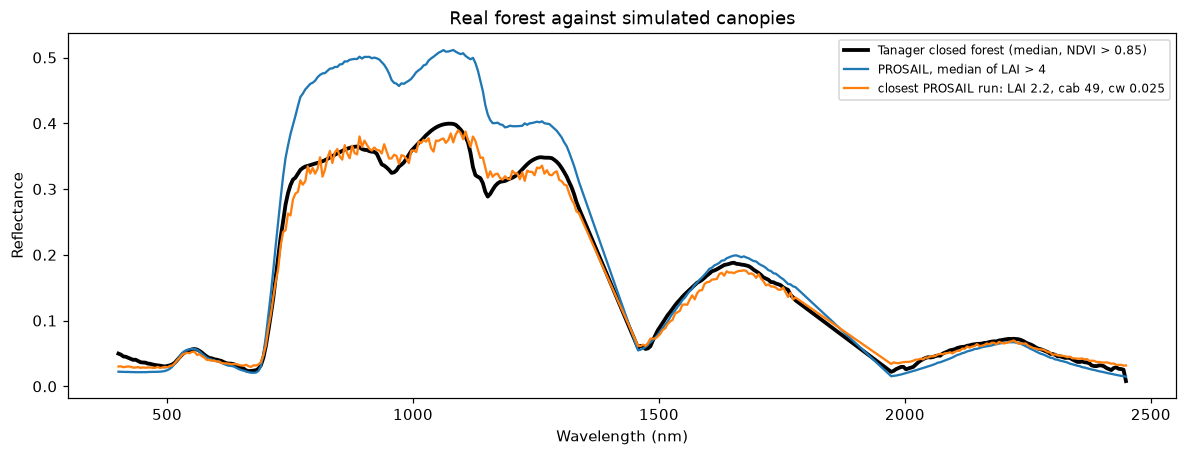

In [12]:
ndvi = hs.index(cube, "NDVI").values
forest = np.nanmedian(cube.values[:, ndvi > 0.85], axis=1)  # median closed-forest spectrum
Ps, Ss = hyb["lut"]  # LUT parameters and spectra used by the hybrid model
dense = np.median(Ss[Ps["lai"].to_numpy() > 4], axis=0)  # median simulated canopy with LAI > 4
near = int(np.argmin(np.linalg.norm(Ss - forest, axis=1)))  # closest simulation in absolute terms
fig, ax = plt.subplots(figsize=(13, 4.3))
ax.plot(wl, forest, lw=2.5, color="k", label="Tanager closed forest (median, NDVI > 0.85)")
ax.plot(wl, dense, label="PROSAIL, median of LAI > 4")
ax.plot(wl, Ss[near], label=f"closest PROSAIL run: LAI {Ps['lai'][near]:.1f}, cab {Ps['cab'][near]:.0f}, cw {Ps['cw'][near]:.3f}")
ax.set(xlabel="Wavelength (nm)", ylabel="Reflectance", title="Real forest against simulated canopies"); ax.legend(fontsize=8)
plt.show()

The visible and SWIR of the real forest match dense simulated canopies well, but its NIR plateau is
about 0.15 lower (0.35 to 0.40 against 0.45 to 0.50). PROSAIL treats the canopy as a uniform layer
of leaves (a turbid medium): it has no tree crowns, no gaps and no shadows between them. In a forest
seen at 30 m, shadows between crowns lower the NIR, the region that carries LAI, so the best matching
simulation is a much sparser canopy (LAI about 2) with wet, chlorophyll rich leaves, and the GPR,
trained on noisy samples, goes lower still. That is exactly what the retrieval reports. PROSAIL based hybrid models are designed for crops and grasslands; forests need
models with crown geometry (for example INFORM or DART) or empirical calibration with field data.


## Where can the model be trusted?

A hybrid model only knows the spectra in its look-up table. The spectral angle from each pixel to
its closest simulated spectrum measures how far outside the training space the pixel lies.


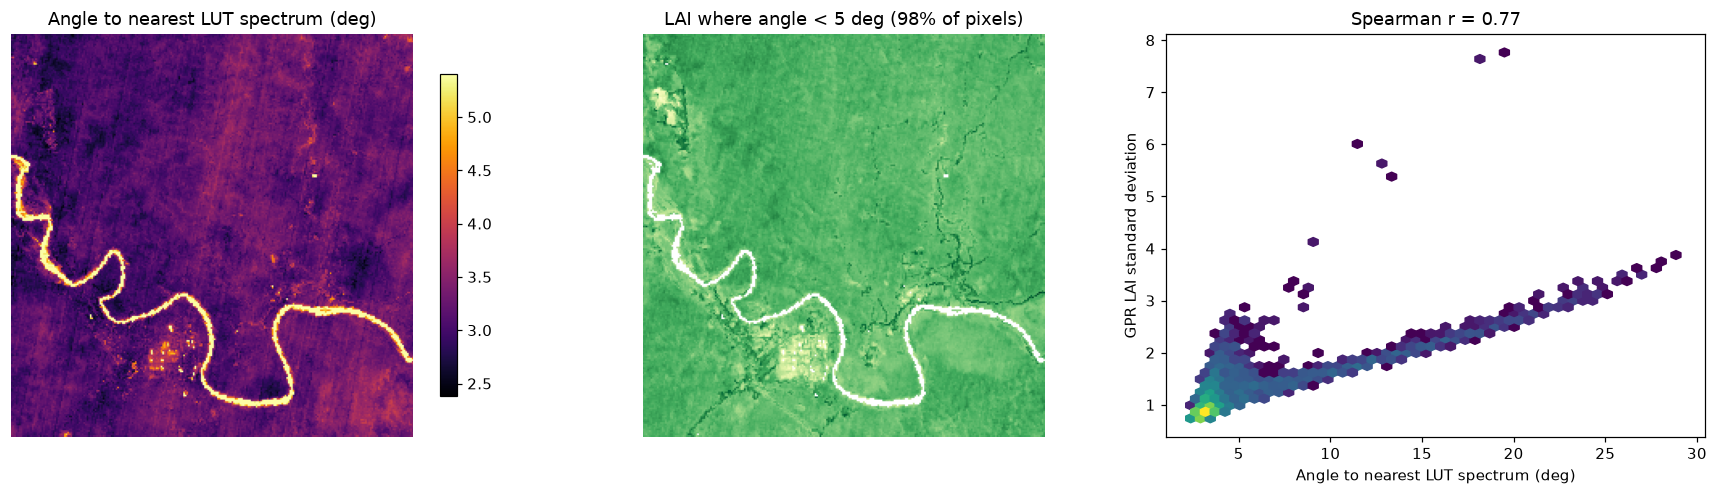

In [13]:
X = cube.values.reshape(cube.sizes["band"], -1).T  # (pixels, bands)
ok = np.all(np.isfinite(X), 1)
Xn = X[ok] / np.linalg.norm(X[ok], axis=1, keepdims=True)  # unit vectors
L = hyb["lut"][1]
Ln = L / np.linalg.norm(L, axis=1, keepdims=True)
best = np.full(len(X), np.nan)
for s in range(0, len(Xn), 20000):  # nearest LUT spectrum by angle, in chunks
    best[np.flatnonzero(ok)[s:s + 20000]] = np.degrees(np.arccos(np.clip((Xn[s:s + 20000] @ Ln.T).max(1), -1, 1)))
angle = best.reshape(cube.shape[1:])
sd = maps["lai_std"].values
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
im = axes[0].imshow(angle, cmap="inferno", vmax=np.nanpercentile(angle, 98)); axes[0].set_title("Angle to nearest LUT spectrum (deg)")
plt.colorbar(im, ax=axes[0], shrink=0.8)
trusted = angle < 5  # within 5 degrees of a simulated canopy
axes[1].imshow(np.where(trusted, maps["lai"], np.nan), cmap="YlGn"); axes[1].set_title(f"LAI where angle < 5 deg ({trusted.mean():.0%} of pixels)")
m = np.isfinite(angle) & np.isfinite(sd)
axes[2].hexbin(angle[m], sd[m], gridsize=50, bins="log", cmap="viridis")
axes[2].set(xlabel="Angle to nearest LUT spectrum (deg)", ylabel="GPR LAI standard deviation",
            title=f"Spearman r = {spearmanr(angle[m], sd[m])[0]:.2f}")
for ax in axes[:2]:
    ax.axis("off")
plt.tight_layout()
plt.show()

The river, the town and roads are far outside the table, because PROSAIL simulates only vegetation
over soil, and the spectral angle correlates with the GPR standard deviation (Spearman r about
0.77): two independent signs of extrapolation, which mask these pixels well. But 98 percent of the
pixels, including the whole forest, pass the 5 degree test. The spectral angle ignores brightness,
and the forest's *shape* resembles some simulated canopy even though its physics does not. Domain
checks catch spectra that are obviously foreign; they cannot catch a model that is wrong for the
vegetation type. In practice, choose a radiative transfer model suited to the canopy, restrict the
LUT ranges to what is plausible for the crop or biome, and validate with field data (for example by
fitting `hs.fit_plsr` to spectra extracted at field plots with `hs.spectra_at`).


## Summary and exercises

**Key points**

- PROSAIL links leaf biochemistry and canopy structure to reflectance; each trait has its own
  spectral signature, and some (carotenoids, leaf angle) are weakly expressed.
- Global sensitivity analysis on a look-up table predicts which traits can be retrieved.
- PLSR, random forests and GPR invert noisy simulations with similar skill for LAI, chlorophyll and
  water; VIP scores and sensitivity curves explain which bands matter.
- Hybrid retrieval maps traits quickly, and GPR adds a standard deviation that flags spectra unlike
  the training data, but it does not rank errors inside the training space.
- Applied to a closed forest, a PROSAIL (turbid medium) model gives plausible patterns but wrong
  values: crown shadows and gaps make the forest look like a sparse canopy. Spectral angle and GPR
  uncertainty catch foreign surfaces (water, town) but not a wrong model. Field validation and a
  canopy model suited to the vegetation remain essential.

**`geolattice.rsense.hyperspectral` functions used:** `read_tanager`, `read_tanager_ancillary`,
`drop_bad_bands`, `prosail_spectrum`, `prosail_lut`, `fit_plsr`, `fit_regressor`, `vip_scores`
(through `fit_plsr`), `hybrid_retrieval`, `index`, `plot_rgb`.

**Exercises**

1. Restrict the LUT to dense canopies (`ranges={"lai": (2, 7)}`) and retrain. Does the test RMSE for
   chlorophyll improve?
2. Retrain the PLSR for chlorophyll with `preprocess=` set to a first derivative (for example
   `lambda X: np.gradient(X, axis=1)`). How do the components and VIP change?
3. Increase the LUT noise to 5 percent. Which trait suffers most?
4. Run `hybrid_retrieval` with `model="rf"`. Where do the RF and GPR maps differ most?
